# Vitalia Analytics: análisis y modelado

Este notebook documenta el proyecto de analítica de datos solicitado: limpieza del dataset, exploración, entrenamiento de una regresión logística y una red neuronal artificial, y evaluación mediante métricas y matrices de confusión.

La variable objetivo es la clasificación del caso como dengue no complicado o dengue complicado. El análisis utiliza los cinco predictores seleccionados en el artículo de referencia: PCV, plaquetas, WBC máximo, ALT e hipotensión a la admisión.

## 1. Importación y carga de datos

In [1]:
from pathlib import Path
import re
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score, ConfusionMatrixDisplay,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
ROOT = Path.cwd()
if not (ROOT / "MASTER_CHART_F1000Research.xlsx").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "MASTER_CHART_F1000Research.xlsx"
OUTPUT_PATH = ROOT / "outputs"
OUTPUT_PATH.mkdir(exist_ok=True)

raw = pd.read_excel(DATA_PATH)
print(f"Registros: {raw.shape[0]} | Columnas: {raw.shape[1]}")
display(raw.head())

Registros: 303 | Columnas: 25


,GROUPS: DENGUE FEVER OR COMPLICATED DENGUE,AGE,GENDER,DURATION OF FEVER,HEADACHE,MYALGIA,ABDOMINAL PAIN,RASH,VOMITING,BREATHLESSNESS,...,LOWEST WBC,HIGHEST WBC,PLATELET COUNT,ALT,CREATININE,FERRITIN,IV FLUIDS,ANTIBIOTICS,ANTIPYRETICS,STEROIDS
0,2,2,1,3,2,1,2,2,1,2,...,3400,5100,30000,53.0,0.62,4167.0,1,1,2,1
1,2,2,1,4,2,1,2,2,2,2,...,3000,5300,43000,21.0,0.43,108.0,1,2,2,2
2,1,1,2,3,2,1,2,2,2,2,...,2300,2600,129000,12.0,0.34,212.0,1,1,1,2
3,1,2,2,5,2,1,2,2,2,2,...,1500,4800,70000,171.0,0.80,1429.0,1,1,1,1
4,1,2,2,3,2,1,2,2,2,2,...,8600,9100,184000,45.0,0.44,NaN,1,2,1,2


## 2. Revisión inicial y limpieza

Se normalizan los nombres, se eliminan duplicados y se revisan tipos, valores faltantes y distribución de la variable objetivo. No se utilizarán las variables de tratamiento porque pueden representar información posterior a la evaluación inicial. Ferritina tampoco se incluye en el modelo principal debido a su alta cantidad de datos faltantes.

In [2]:
def normalize_column_name(value):
    text = unicodedata.normalize("NFKD", str(value)).encode("ascii", "ignore").decode("ascii")
    text = text.lower().strip()
    return re.sub(r"[^a-z0-9]+", "_", text).strip("_")

data = raw.copy()
data.columns = [normalize_column_name(column) for column in data.columns]
print("Valores faltantes por columna:")
display(data.isna().sum().sort_values(ascending=False).to_frame("faltantes").head(10))
print(f"Duplicados encontrados: {data.duplicated().sum()}")
data = data.drop_duplicates().copy()

# Conversión de códigos: 1 = no complicado, 2 = complicado.
data["target"] = pd.to_numeric(data["groups_dengue_fever_or_complicated_dengue"], errors="coerce").map({1: 0, 2: 1})

# Selección de variables de admisión definidas en el artículo.
features = {
    "pcv": "pcv",
    "platelets": "platelet_count",
    "wbc_max": "highest_wbc",
    "alt": "alt",
    "hypotension": "bp_at_admission",
}
model_data = pd.DataFrame({name: pd.to_numeric(data[column], errors="coerce") for name, column in features.items()})
# En el README del dataset, BP=1 significa hipotensión y BP=2 significa no hipotensión.
model_data["hypotension"] = model_data["hypotension"].map({1: 1, 2: 0})
y = data["target"].astype(int)

cleaning_summary = pd.DataFrame({
    "Registros originales": [len(raw)],
    "Duplicados eliminados": [len(raw) - len(data)],
    "Registros finales": [len(model_data)],
    "ALT faltante": [model_data["alt"].isna().sum()],
    "Clases": [y.value_counts().to_dict()],
})
display(cleaning_summary)
display(model_data.describe().T)

Valores faltantes por columna:


,faltantes
ferritin,112
alt,1
creatinine,1
age,0
headache,0
myalgia,0
gender,0
duration_of_fever,0
groups_dengue_fever_or_complicated_dengue,0
vomiting,0


Duplicados encontrados: 1


,Registros originales,Duplicados eliminados,Registros finales,ALT faltante,Clases
0,303,1,302,1,"{0: 239, 1: 63}"


,count,mean,std,min,25%,50%,75%,max
pcv,302.0,40.097351,4.036790,28.5,37.8,39.85,42.3,54.6
platelets,302.0,101922.847682,66312.400998,11000.0,55000.0,89500.00,129750.0,479000.0
wbc_max,302.0,5733.543046,3143.255559,1500.0,3600.0,5150.00,6975.0,24100.0
alt,301.0,67.098007,139.728777,5.0,17.0,26.00,53.0,1481.0
hypotension,302.0,0.874172,0.332206,0.0,1.0,1.00,1.0,1.0


## 3. Exploración visual

C:\Users\Mi PC\AppData\Local\Temp\ipykernel_25504\1415475026.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y.map({0: "No complicado", 1: "Complicado"}), ax=axes[0], palette="Set2")


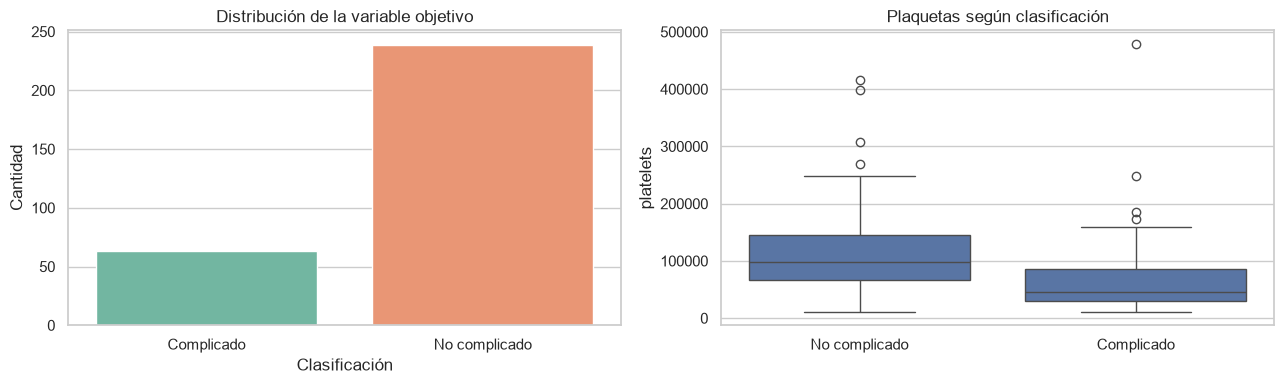

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x=y.map({0: "No complicado", 1: "Complicado"}), ax=axes[0], palette="Set2")
axes[0].set_title("Distribución de la variable objetivo")
axes[0].set_xlabel("Clasificación")
axes[0].set_ylabel("Cantidad")

sns.boxplot(data=model_data.assign(target=y), x="target", y="platelets", ax=axes[1])
axes[1].set_title("Plaquetas según clasificación")
axes[1].set_xticks([0, 1], ["No complicado", "Complicado"])
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

## 4. Separación de datos y construcción de pipelines

El imputador y el escalador se ajustan dentro del pipeline, usando únicamente los datos de entrenamiento. Esto evita fuga de información. La división es estratificada para conservar la proporción de clases.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    model_data, y, test_size=0.25, stratify=y, random_state=42
)

def make_pipeline(model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model),
    ])

models = {
    "Regresión logística": make_pipeline(LogisticRegression(
        max_iter=2000, class_weight="balanced", solver="liblinear", random_state=42
    )),
    "Red neuronal artificial": make_pipeline(MLPClassifier(
        hidden_layer_sizes=(16, 8), activation="relu", solver="lbfgs",
        alpha=0.001, max_iter=2000, random_state=42
    )),
}

predictions = {}
probabilities = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    probabilities[name] = model.predict_proba(X_test)[:, 1]

print(f"Entrenamiento: {len(X_train)} registros | Prueba: {len(X_test)} registros")

Entrenamiento: 226 registros | Prueba: 76 registros


## 5. Evaluación de los modelos

,Accuracy,Precision,Recall,F1,ROC-AUC
Regresión logística,0.816,0.536,0.938,0.682,0.922
Red neuronal artificial,0.882,0.684,0.812,0.743,0.802


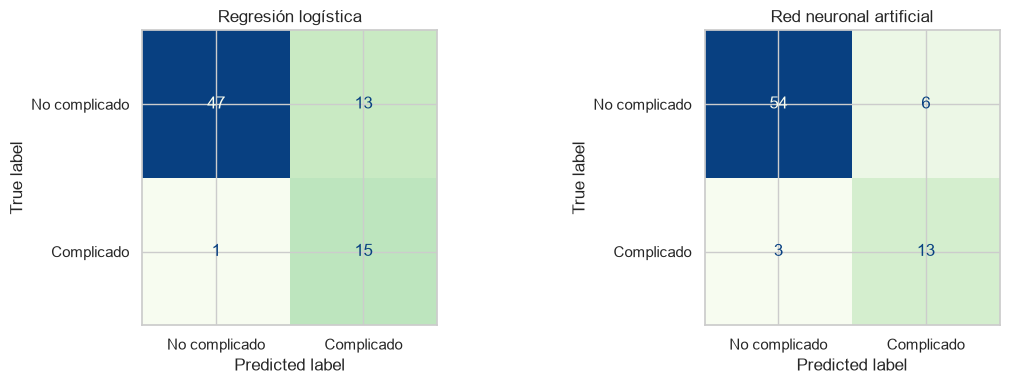

In [5]:
def calculate_metrics(y_true, y_pred, probability):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probability),
    }

holdout_metrics = pd.DataFrame({
    name: calculate_metrics(y_test, predictions[name], probabilities[name])
    for name in models
}).T
display(holdout_metrics.style.format("{:.3f}"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, (name, prediction) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, prediction, display_labels=["No complicado", "Complicado"],
        cmap="GnBu", ax=axis, colorbar=False
    )
    axis.set_title(name)
plt.tight_layout()
plt.show()

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
cv_results = {}
for name, model in models.items():
    scores = cross_validate(model, model_data, y, cv=cv, scoring=scoring)
    cv_results[name] = {metric: scores[f"test_{metric}"].mean() for metric in scoring}
cv_table = pd.DataFrame(cv_results).T
display(cv_table.style.format("{:.3f}"))

# Los coeficientes de la regresión logística se muestran sobre variables estandarizadas.
logistic_coefficients = pd.Series(
    models["Regresión logística"].named_steps["model"].coef_[0],
    index=model_data.columns,
).sort_values(key=abs, ascending=False)
display(logistic_coefficients.to_frame("Coeficiente estandarizado"))

,accuracy,precision,recall,f1,roc_auc
Regresión logística,0.821,0.562,0.715,0.627,0.852
Red neuronal artificial,0.795,0.502,0.529,0.513,0.722


,Coeficiente estandarizado
hypotension,-0.799780
platelets,-0.687158
alt,0.644266
wbc_max,0.394827
pcv,0.223153


## 6. Puntaje complementario del artículo

El artículo asigna 1 punto a PCV, plaquetas, WBC y ALT cuando superan sus puntos de corte, y 3 puntos a la hipotensión. Un resultado de 2 o más se interpreta como mayor riesgo en el estudio original. Este puntaje se presenta como apoyo interpretativo y no reemplaza las predicciones de los modelos.

In [7]:
score = (
    (model_data["pcv"] >= 42).astype(int)
    + (model_data["platelets"] <= 75000).astype(int)
    + (model_data["wbc_max"] >= 7000).astype(int)
    + (model_data["alt"] >= 70).astype(int)
    + 3 * (model_data["hypotension"] == 1).astype(int)
)
score_summary = pd.DataFrame({
    "puntaje": score,
    "clasificacion_articulo": np.where(score >= 2, "Mayor riesgo", "Menor riesgo"),
    "clase_real": y.map({0: "No complicado", 1: "Complicado"}),
})
display(score_summary.groupby("clasificacion_articulo").size().to_frame("cantidad"))

score_summary.to_csv(OUTPUT_PATH / "score_complementario.csv", index=False)
model_data.assign(target=y).to_csv(OUTPUT_PATH / "datos_limpios_modelado.csv", index=False)
holdout_metrics.to_csv(OUTPUT_PATH / "metricas_holdout.csv")
cv_table.to_csv(OUTPUT_PATH / "metricas_validacion_cruzada.csv")
print(f"Resultados guardados en: {OUTPUT_PATH}")

,cantidad
clasificacion_articulo,
Mayor riesgo,289
Menor riesgo,13


Resultados guardados en: c:\1-Universidad\6to\Analitica de datos\Maye\Dengue\outputs


## Conclusión

Se construyeron dos modelos de clasificación binaria con un pipeline reproducible. La regresión logística permite interpretar la dirección e importancia relativa de las variables, mientras que la red neuronal ofrece una alternativa no lineal. Las métricas deben interpretarse considerando el tamaño reducido y el desbalance del dataset.